<a href="https://colab.research.google.com/github/nehasingh913833-gif/Parametric-and-Non-parametric-Brain-Function-Connectivity-Approach-for-Predicting-Autism./blob/main/2dautismclassifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ==========================================
# STEP 1: IMPORTS & ENVIRONMENT SETUP
# ==========================================
!pip install -q nilearn==0.13.0 scikit-learn seaborn matplotlib

import warnings
warnings.filterwarnings('ignore')
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nilearn.datasets import fetch_abide_pcp
from nilearn.connectome import ConnectivityMeasure

from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, roc_curve, auc, roc_auc_score
)

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, regularizers

# Set seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print("Environment Ready. Starting Optimized ABIDE Pipeline (Pearson + 2D CNN)...")

Environment Ready. Starting Optimized ABIDE Pipeline (Pearson + 2D CNN)...


In [ ]:

# ==========================================
# STEP 2: FETCH 1000 SAMPLES & CLEAN
# ==========================================
N_SAMPLES = 1000

abide = fetch_abide_pcp(
    n_subjects=N_SAMPLES,
    pipeline='cpac',
    band_pass_filtering=True,
    global_signal_regression=True,
    derivatives=['rois_aal'],
    quality_checked=False,
    verbose=0
)

raw_time_series = abide.rois_aal[:N_SAMPLES]
# DX_GROUP: 1 = Autism (ASD), 2 = Control -> Binary: 1 = ASD, 0 = Control
y = (np.asarray(abide.phenotypic['DX_GROUP'])[:N_SAMPLES] == 1).astype(np.int32)

time_series_list = []
rng = np.random.default_rng(42)
for ts in raw_time_series:
    ts = np.asarray(ts, dtype=np.float32)
    zero_std_cols = np.std(ts, axis=0) < 1e-8
    if np.any(zero_std_cols):
        ts[:, zero_std_cols] += rng.normal(0, 1e-5, size=(ts.shape[0], np.sum(zero_std_cols)))
    time_series_list.append(ts)

n_rois = time_series_list[0].shape[1]
print(f"Loaded {len(time_series_list)} subjects | Matrix Size: {n_rois}x{n_rois} | ASD (1): {np.sum(y==1)}, Control (0): {np.sum(y==0)}")

Loaded 1000 subjects | Matrix Size: 116x116 | ASD (1): 488, Control (0): 512


In [ ]:
# ==========================================
# STEP 3: PARAMETRIC PEARSON 2D MATRIX FORM
# ==========================================
print("Computing Parametric Pearson 2D Connectivity Matrices...")
pearson_measure = ConnectivityMeasure(kind='correlation')
pearson_matrices = np.nan_to_num(pearson_measure.fit_transform(time_series_list), nan=0.0)

# Zero out the main diagonal (self-correlations = 1.0) and apply Fisher's r-to-z transform
for i in range(len(pearson_matrices)):
    np.fill_diagonal(pearson_matrices[i], 0.0)

X_fisher_2d = np.arctanh(np.clip(pearson_matrices, -0.9999, 0.9999))

# 2D Spatial Feature Masking: Keep top K most informative ROI-to-ROI cells in the 2D grid
K_BEST_EDGES = 800
triu_idx = np.triu_indices(n_rois, k=1)
X_upper = X_fisher_2d[:, triu_idx[0], triu_idx[1]]

selector = SelectKBest(score_func=f_classif, k=K_BEST_EDGES)
X_upper_selected = selector.fit_transform(X_upper, y)
X_upper_scaled = StandardScaler().fit_transform(X_upper_selected)

# Reconstruct the 2D Symmetric Matrix (N, 116, 116, 1) with only the top K discriminative edges
selected_mask = selector.get_support()
sel_rows = triu_idx[0][selected_mask]
sel_cols = triu_idx[1][selected_mask]

X_2d = np.zeros((N_SAMPLES, n_rois, n_rois), dtype=np.float32)
X_2d[:, sel_rows, sel_cols] = X_upper_scaled
X_2d[:, sel_cols, sel_rows] = X_upper_scaled  # Preserve matrix symmetry
X_2d = X_2d[..., np.newaxis]  # Add channel dimension -> (1000, 116, 116, 1)

print(f"2D Matrix Input Shape: {X_2d.shape}")

del raw_time_series, time_series_list, pearson_matrices, X_fisher_2d, X_upper
gc.collect()


Computing Parametric Pearson 2D Connectivity Matrices...
2D Matrix Input Shape: (1000, 116, 116, 1)


30

In [ ]:
# ==========================================
# STEP 4: DEFINE 2D CNN ARCHITECTURE
# ==========================================
def build_2d_cnn(input_shape):
    model = models.Sequential([
        layers.Input(shape=input_shape),

        layers.Conv2D(16, kernel_size=(3, 3), padding='same', kernel_regularizer=regularizers.l2(1e-3)),
        layers.BatchNormalization(),
        layers.Activation('elu'),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.3),

        layers.Conv2D(32, kernel_size=(3, 3), padding='same', kernel_regularizer=regularizers.l2(1e-3)),
        layers.BatchNormalization(),
        layers.Activation('elu'),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.3),

        layers.Flatten(),
        layers.Dense(64, activation='elu', kernel_regularizer=regularizers.l2(1e-3)),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=5e-4),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

In [ ]:
# ==========================================
# STEP 5: 5-FOLD STRATIFIED CROSS-VALIDATION
# ==========================================
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
all_y_true, all_y_prob, all_y_pred = [], [], []

print("\nStarting 5-Fold Cross-Validation for 2D CNN...")

for fold, (train_idx, val_idx) in enumerate(skf.split(X_2d, y), 1):
    tf.keras.backend.clear_session()

    X_train, X_val = X_2d[train_idx], X_2d[val_idx]
    y_train, y_val = y[train_idx], y[val_idx]

    model = build_2d_cnn(X_2d.shape[1:])

    early_stop = callbacks.EarlyStopping(
        monitor='val_accuracy', mode='max', patience=10, restore_best_weights=True
    )
    lr_sched = callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=4, min_lr=1e-5, verbose=0
    )

    model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=50,
        batch_size=32,
        callbacks=[early_stop, lr_sched],
        verbose=0
    )

    # Direct tensor call avoids tf.function retracing warnings
    y_prob = model(X_val, training=False).numpy().ravel()
    y_pred = (y_prob >= 0.5).astype(int)

    fold_acc = accuracy_score(y_val, y_pred)
    print(f"Fold {fold}/5 -> Accuracy: {fold_acc*100:.2f}% | ROC-AUC: {roc_auc_score(y_val, y_prob):.4f}")

    all_y_true.extend(y_val)
    all_y_prob.extend(y_prob)
    all_y_pred.extend(y_pred)


Starting 5-Fold Cross-Validation for 2D CNN...
Fold 1/5 -> Accuracy: 74.00% | ROC-AUC: 0.7757
Fold 2/5 -> Accuracy: 67.00% | ROC-AUC: 0.7175
Fold 3/5 -> Accuracy: 67.50% | ROC-AUC: 0.7424
Fold 4/5 -> Accuracy: 70.00% | ROC-AUC: 0.7705
Fold 5/5 -> Accuracy: 75.50% | ROC-AUC: 0.8046



=== FINAL 5-FOLD RESULTS (2D CNN) ===


,Approach,Connectome,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Parametric,Pearson (2D Matrix),2D CNN,0.708,0.7248,0.6475,0.684,0.7499


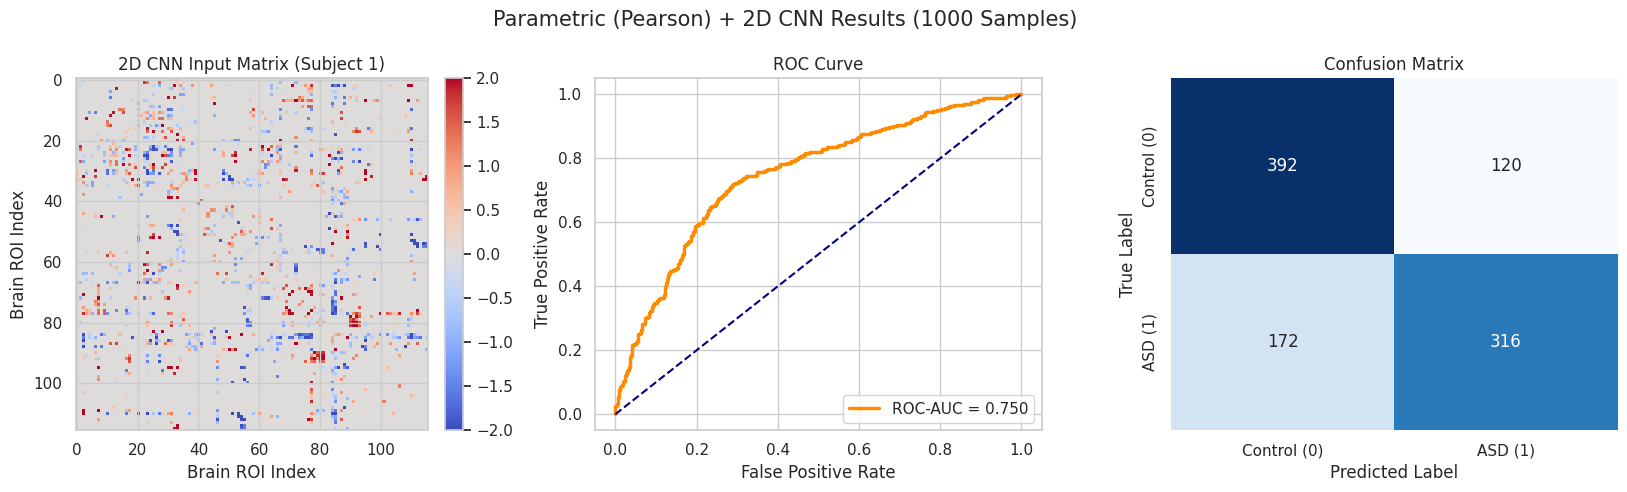

In [ ]:
# ==========================================
# STEP 6: FINAL METRICS & VISUALIZATIONS
# ==========================================
cm = confusion_matrix(all_y_true, all_y_pred)
metrics = {
    'Approach': 'Parametric',
    'Connectome': 'Pearson (2D Matrix)',
    'Model': '2D CNN',
    'Accuracy': accuracy_score(all_y_true, all_y_pred),
    'Precision': precision_score(all_y_true, all_y_pred, zero_division=0),
    'Recall': recall_score(all_y_true, all_y_pred, zero_division=0),
    'F1-Score': f1_score(all_y_true, all_y_pred, zero_division=0),
    'ROC-AUC': roc_auc_score(all_y_true, all_y_prob)
}

print("\n=== FINAL 5-FOLD RESULTS (2D CNN) ===")
display(pd.DataFrame([metrics]).round(4))

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
fig.suptitle("Parametric (Pearson) + 2D CNN Results (1000 Samples)", fontsize=15)

# 1. Sample 2D Connectivity Matrix Input
im = axes[0].imshow(X_2d[0, :, :, 0], cmap='coolwarm', vmin=-2, vmax=2)
axes[0].set_title("2D CNN Input Matrix (Subject 1)")
axes[0].set_xlabel("Brain ROI Index")
axes[0].set_ylabel("Brain ROI Index")
fig.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)

# 2. ROC Curve
fpr, tpr, _ = roc_curve(all_y_true, all_y_prob)
axes[1].plot(fpr, tpr, color='darkorange', lw=2.5, label=f"ROC-AUC = {auc(fpr, tpr):.3f}")
axes[1].plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--')
axes[1].set_title("ROC Curve")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend(loc="lower right")

# 3. Confusion Matrix
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[2], cbar=False,
            xticklabels=['Control (0)', 'ASD (1)'], yticklabels=['Control (0)', 'ASD (1)'])
axes[2].set_title("Confusion Matrix")
axes[2].set_xlabel("Predicted Label")
axes[2].set_ylabel("True Label")

plt.tight_layout()
plt.show()



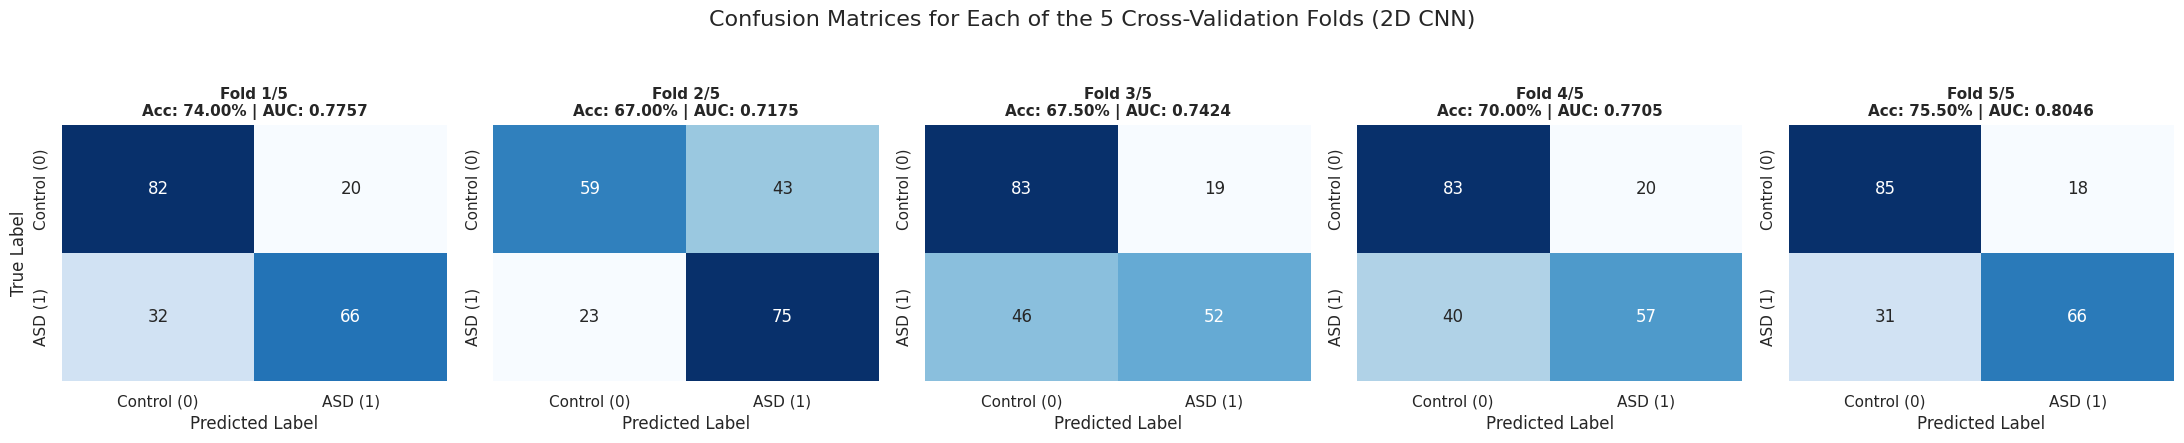

In [ ]:
# --- ADDITIONAL CODE: PLOT 5 CONFUSION MATRICES (NO RE-TRAINING NEEDED) ---
fold_size = len(all_y_true) // 5  # 200 validation samples per fold

fig, axes = plt.subplots(1, 5, figsize=(22, 4.2))
fig.suptitle("Confusion Matrices for Each of the 5 Cross-Validation Folds (2D CNN)", fontsize=16, y=1.05)

for i in range(5):
    start_idx = i * fold_size
    end_idx = (i + 1) * fold_size

    # Slice the stored results for Fold i+1
    y_true_fold = all_y_true[start_idx:end_idx]
    y_pred_fold = all_y_pred[start_idx:end_idx]
    y_prob_fold = all_y_prob[start_idx:end_idx]

    cm_fold = confusion_matrix(y_true_fold, y_pred_fold)
    acc_fold = accuracy_score(y_true_fold, y_pred_fold)
    auc_fold = roc_auc_score(y_true_fold, y_prob_fold)

    sns.heatmap(
        cm_fold, annot=True, fmt='d', cmap='Blues', ax=axes[i], cbar=False,
        xticklabels=['Control (0)', 'ASD (1)'],
        yticklabels=['Control (0)', 'ASD (1)']
    )
    axes[i].set_title(f"Fold {i+1}/5\nAcc: {acc_fold*100:.2f}% | AUC: {auc_fold:.4f}", fontsize=11, fontweight='bold')
    axes[i].set_xlabel("Predicted Label")
    axes[i].set_ylabel("True Label" if i == 0 else "")

plt.tight_layout()
plt.show()